# Differential machine learning, step by step

Each section: the point from the paper (paraphrased, section numbers from [arXiv 2005.02347](https://arxiv.org/abs/2005.02347)), a small run, then the full results from `run_all.py`.

In [1]:
import csv
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "experiments"))

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Image

from diffml.evaluate import print_table, rmse
from diffml.train import train
from diffml.utils import set_seed

set_seed(42)
%matplotlib inline


def show_table(name, columns=None):
    # print one of the CSV tables written by run_all.py
    def parse(v):
        for kind in (int, float):
            try:
                return kind(v)
            except ValueError:
                pass
        return v

    with open(ROOT / "results" / f"{name}.csv") as f:
        rows = [{k: parse(v) for k, v in r.items() if columns is None or k in columns}
                for r in csv.DictReader(f)]
    print_table(rows)

## 1. One path, one noisy label

> **Paper, Section 1.2.1 (paraphrased).** To learn a pricing function by simulation, each training input gets the payoff of a single simulated path as its label. That label is an unbiased estimate of the price, so a regression on enough of them converges to the true pricing function. The pathwise derivative of the same payoff with respect to the inputs is an unbiased estimate of the Greeks, and costs little extra to compute (the paper uses AAD). For a call, the pathwise delta is 1{S_T > K} · S_T / S_0.

Labels for a Black-Scholes call, 1,000 spots between 40 and 160.

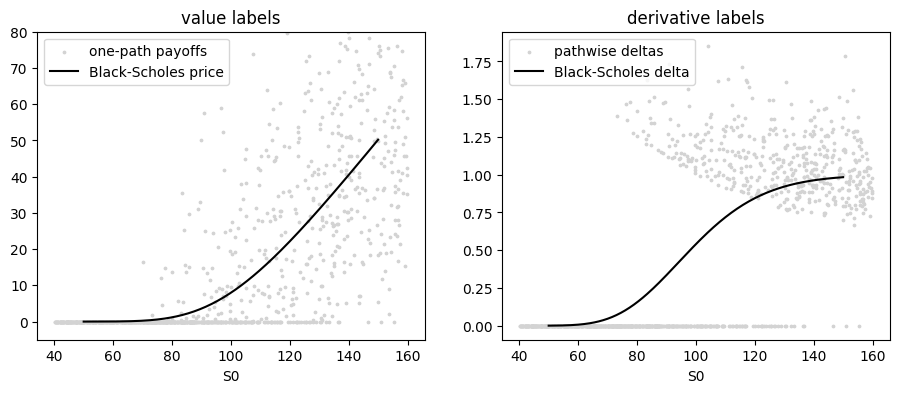

In [2]:
from diffml.analytics.black_scholes import bs_delta, bs_price
from diffml.data.black_scholes import simulate_option

K, vol, T = 100.0, 0.2, 1.0
x, y, dydx = simulate_option(1000, np.random.default_rng(1), K, vol, T)

S_grid = np.linspace(50, 150, 201)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.scatter(x, y, s=3, color="lightgrey", label="one-path payoffs")
ax1.plot(S_grid, bs_price(S_grid, K, vol, T), "k", label="Black-Scholes price")
ax1.set_ylim(-5, 80)
ax1.set_title("value labels")
ax2.scatter(x, dydx, s=3, color="lightgrey", label="pathwise deltas")
ax2.plot(S_grid, bs_delta(S_grid, K, vol, T), "k", label="Black-Scholes delta")
ax2.set_title("derivative labels")
for ax in (ax1, ax2):
    ax.set_xlabel("S0")
    ax.legend()
plt.show()

Each dot is a bad estimate on its own, but both clouds sit on the true curves.

## 2. The twin network

> **Paper, Section 1.2 (paraphrased).** The derivatives of a network's output with respect to its inputs can be computed by backpropagation through the network itself. Put together, the forward pass and this backward pass form a "twin network" that outputs the value and all its differentials. The activation has to be continuously differentiable, which rules out ReLU.
>
> **Paper, Section 2 (paraphrased).** All the examples use four hidden layers of 20 softplus units, trained with Adam on normalised data.

In PyTorch: `autograd.grad` with `create_graph=True` (`value_and_gradient`). Check against a finite difference:

In [3]:
from diffml.models.network import MLP, value_and_gradient

this_net = MLP(n_inputs=3)
print(this_net)

x_toy = torch.randn(5, 3)
y_toy, dydx_toy = value_and_gradient(this_net, x_toy)
print("output", tuple(y_toy.shape), " gradient", tuple(dydx_toy.shape))

h = 1e-3
bump = torch.zeros_like(x_toy)
bump[:, 0] = h
fd = (this_net(x_toy + bump) - this_net(x_toy - bump)) / (2 * h)
print("autograd  ", dydx_toy[:, 0].detach().numpy().round(4))
print("finite diff", fd[:, 0].detach().numpy().round(4))

MLP(
  (net): Sequential(
    (0): Linear(in_features=3, out_features=20, bias=True)
    (1): Softplus(beta=1.0, threshold=20.0)
    (2): Linear(in_features=20, out_features=20, bias=True)
    (3): Softplus(beta=1.0, threshold=20.0)
    (4): Linear(in_features=20, out_features=20, bias=True)
    (5): Softplus(beta=1.0, threshold=20.0)
    (6): Linear(in_features=20, out_features=20, bias=True)
    (7): Softplus(beta=1.0, threshold=20.0)
    (8): Linear(in_features=20, out_features=1, bias=True)
  )
)
output (5, 1)  gradient (5, 3)
autograd   [ 0.0003  0.001   0.0001 -0.0003  0.0003]
finite diff [ 0.0003  0.001   0.0001 -0.0003  0.0003]


> **Paper, Section 1.2.1 (paraphrased).** The twin network is trained on the usual mean squared error of the values plus lambda times the mean squared error of the differentials.
>
> **Paper, Appendix 3 (paraphrased).** Each differential's error is scaled so that the terms of the cost are of similar size, and lambda has little effect, so it is generally left at 1.

My loss: alpha · MSE(values) + beta · MSE(differentials), alpha = 1 / (1 + lambda · n). Same as the paper up to a constant.

## 3. Black-Scholes call (M1)

Same 1,000 samples, standard vs twin.

standard  price RMSE 1.263   delta RMSE 0.1172
twin      price RMSE 1.369   delta RMSE 0.0313


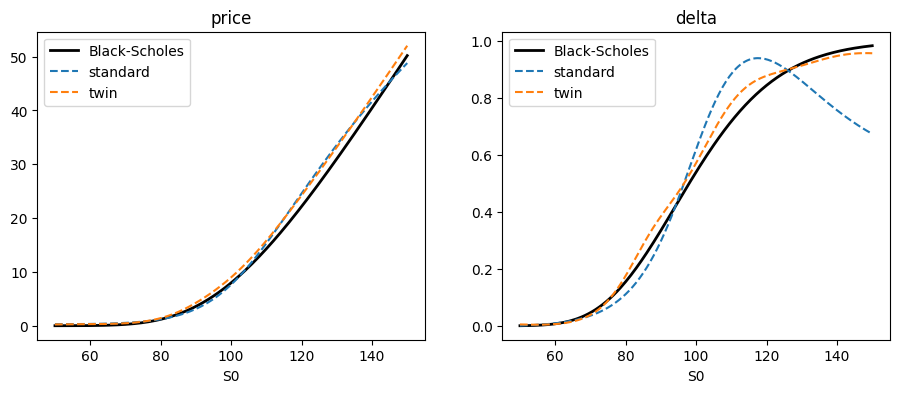

In [4]:
standard = train(x, y, dydx, lambda_=0.0, seed=1)
twin = train(x, y, dydx, lambda_=1.0, seed=1)

true_price, true_delta = bs_price(S_grid, K, vol, T), bs_delta(S_grid, K, vol, T)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(S_grid, true_price, "k", lw=2, label="Black-Scholes")
ax2.plot(S_grid, true_delta, "k", lw=2, label="Black-Scholes")
for name, this_model in [("standard", standard), ("twin", twin)]:
    price, delta = this_model.predict(S_grid[:, None])
    ax1.plot(S_grid, price, "--", label=name)
    ax2.plot(S_grid, delta, "--", label=name)
    print(f"{name:9s} price RMSE {rmse(price, true_price):.3f}   delta RMSE {rmse(delta, true_delta):.4f}")
ax1.set_title("price")
ax2.set_title("delta")
for ax in (ax1, ax2):
    ax.set_xlabel("S0")
    ax.legend()
plt.show()

Prices are close. Delta is where the twin wins. Full results:

In [5]:
show_table("m1_rmse", ["n_train", "model", "price_rmse", "delta_rmse"])

n_train         model  price_rmse  delta_rmse
   1000      standard      1.1897      0.1158
   1000  differential      0.6625      0.0336
   4000      standard      0.5805      0.0326
   4000  differential      0.4987      0.0198
  16000      standard      0.2371      0.0157
  16000  differential      0.6827      0.0160
  64000      standard      0.3898      0.0132
  64000  differential      0.3603      0.0095


Twin delta at 1k is about standard delta at 4k. Twin price at 16k and 64k is off by a constant: derivatives don't fix the level.

## 4. More inputs: Bachelier basket (M2)

> **Paper, Section 2.1 (paraphrased).** A one-year call on a basket of seven assets in a correlated Bachelier model, with basket weights summing to one and correlations generated at random. With cross-validation and early stopping, a twin network trained on 1,000 examples did better than a standard network trained on 64,000 for values, and much better for derivatives.

Each sample gives n derivative labels, so more inputs should mean a bigger gain. 7 assets, 1,000 samples, price against basket value:

standard  price RMSE 0.0107   delta RMSE 0.0694


twin      price RMSE 0.0059   delta RMSE 0.0197


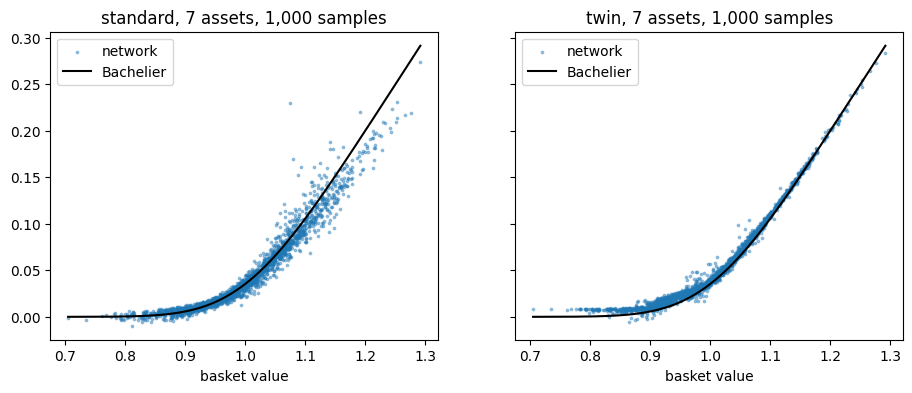

In [6]:
from diffml.data.bachelier_basket import make_basket, sample_spots, simulate_basket

this_basket = make_basket(7, seed=7)
x, y, dydx = simulate_basket(this_basket, 1000, np.random.default_rng(2))
x_test = sample_spots(this_basket, 2000, np.random.default_rng(3))
true_price, true_delta = this_basket.price(x_test), this_basket.delta(x_test)
basket_value = this_basket.basket_value(x_test)
order = np.argsort(basket_value)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (name, lambda_) in zip(axes, [("standard", 0.0), ("twin", 1.0)]):
    this_model = train(x, y, dydx, lambda_=lambda_, seed=2)
    price, delta = this_model.predict(x_test)
    ax.scatter(basket_value, price, s=3, alpha=0.4, label="network")
    ax.plot(basket_value[order], true_price[order], "k", label="Bachelier")
    ax.set_title(f"{name}, 7 assets, 1,000 samples")
    ax.set_xlabel("basket value")
    ax.legend()
    print(f"{name:9s} price RMSE {rmse(price, true_price):.4f}   delta RMSE {rmse(delta, true_delta):.4f}")
plt.show()

All sizes and dimensions (compare the ratio column):

In [7]:
show_table("m2_rmse", ["n_assets", "n_train", "delta_rmse_standard", "delta_rmse_differential", "delta_ratio"])

n_assets  n_train  delta_rmse_standard  delta_rmse_differential  delta_ratio
       1     1000               0.1169                   0.0219       5.3290
       1     4000               0.1031                   0.0086      11.9592
       1    16000               0.0203                   0.0098       2.0770
       1    64000               0.0204                   0.0105       1.9374
       7     1000               0.2720                   0.0090      30.0837
       7     4000               0.0499                   0.0062       8.0024
       7    16000               0.0134                   0.0017       8.0099
       7    64000               0.0106                   0.0012       8.7293
      20     1000               0.0192                   0.0038       5.0726
      20     4000               0.0172                   0.0023       7.3742
      20    16000               0.0146                   0.0026       5.7138
      20    64000               0.0132                   0.0007      19.5178

At 64k the ratio goes 1.9, 8.7, 19.5. The paper's 1k vs 64k claim: roughly yes for delta, no for price.

## 5. Noisy labels: Bachelier swaption (M3)

> **Paper, footnote 3 (paraphrased).** Pathwise derivatives of discontinuous payoffs like digitals and barriers are not well defined, so those payoffs need smoothing first.

Not in the paper. Inputs are forward and vol, so delta and vega together. The payoff is continuous, but the pathwise vega, A · 1{ITM} · √T · Z, is noisy:

In [8]:
import m3_bachelier_swaption as m3
from diffml.data.bachelier_swaption import simulate_swaption

x, y, dydx = simulate_swaption(64000, np.random.default_rng(4), m3.STRIKE, m3.EXPIRY, m3.ANNUITY)
_, true_delta, true_vega = m3.closed_form(x)
for greek, label, true in [("delta", dydx[:, 0], true_delta), ("vega", dydx[:, 1], true_vega)]:
    noise_to_signal = np.sqrt(np.mean((label - true) ** 2) / np.mean(true**2))
    print(f"pathwise {greek}: noise is {noise_to_signal:.2f} times the size of the true {greek}")

pathwise delta: noise is 0.47 times the size of the true delta
pathwise vega: noise is 3.11 times the size of the true vega


n_train         model  price_rmse_bp  delta_rmse  vega_rmse
   1000      standard        22.5332      0.2864     1.3415
   1000  differential        26.8720      0.2180     0.3171
   4000      standard        20.5394      0.4251     0.4683
   4000  differential         6.4071      0.0793     0.1685
  16000      standard         8.1977      0.0634     0.1904
  16000  differential         7.8613      0.0643     0.1029
  64000      standard         7.2436      0.1034     0.2166
  64000  differential         1.7680      0.0306     0.0609


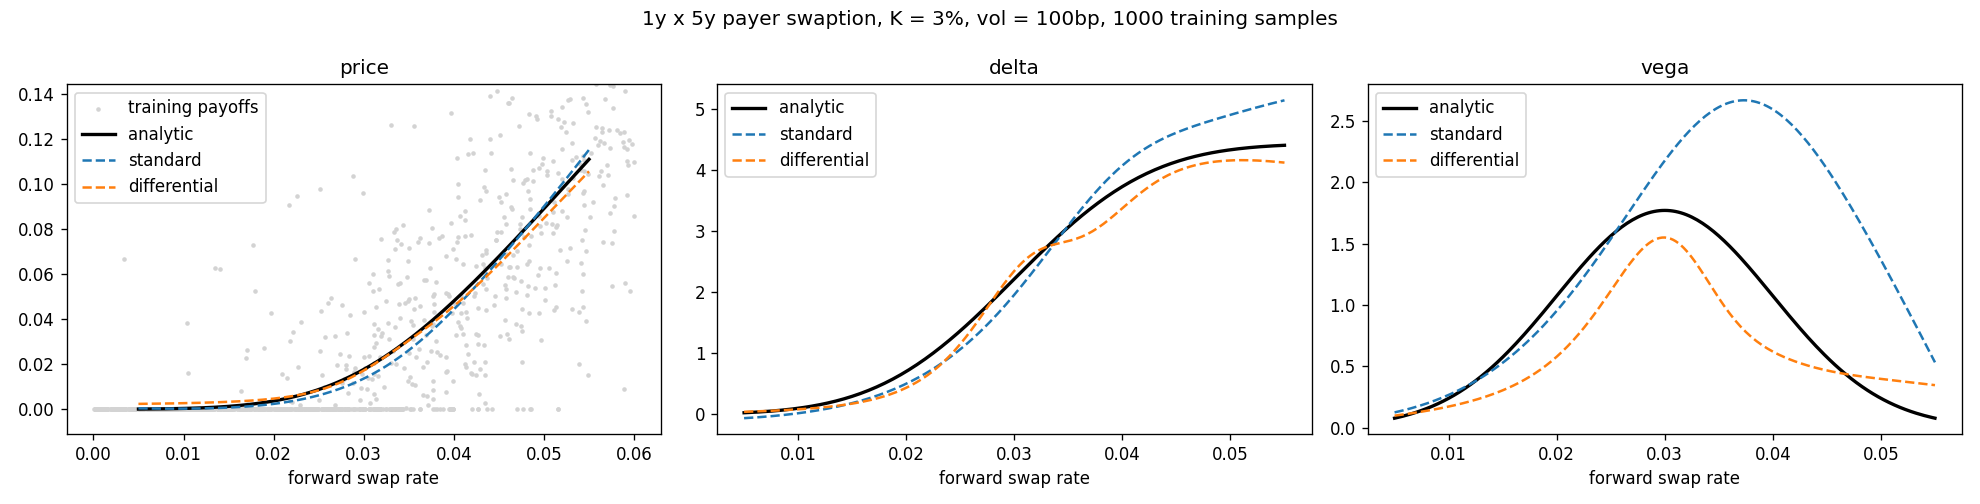

In [9]:
show_table("m3_rmse", ["n_train", "model", "price_rmse_bp", "delta_rmse", "vega_rmse"])
Image(filename=str(ROOT / "results" / "m3_fit_small.png"))

Twin still wins on vega, but it's the weakest result. Labels this noisy limit the gain.

## 6. Hull-White swaption with pillar DV01s (M4)

> **Paper, Section 2.3 (paraphrased).** A real netting set of swaps, cross-currency swaps and swaptions in ten currencies, under a multi-factor Cheyette model with well over a hundred inputs. A twin network trained on 8,000 samples beat a standard network trained on 64,000.

No exact answer in that example. Here: 5y x 10y payer under Hull-White, 10 zero rates as inputs, DV01s from autograd. Training curves:

strike (forward swap rate on the base curve): 4.1073%


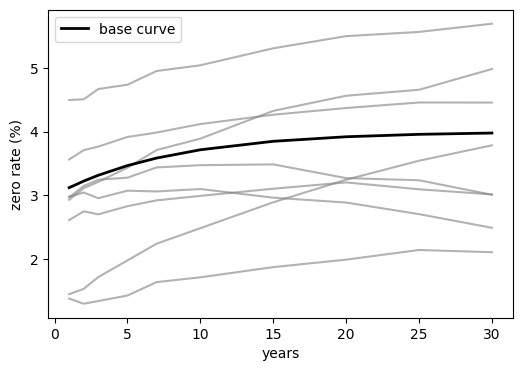

In [10]:
from diffml.analytics.hull_white import HullWhite, Swaption, atm_strike, bumped_dv01, jamshidian_price
from diffml.data.curves import BASE_CURVE, PILLAR_NAMES, PILLARS, sample_curves
from diffml.data.hull_white_swaption import monte_carlo, simulate_hw_swaption

hw = HullWhite(a=0.03, sigma=0.01)
this_swaption = Swaption(T=5.0, tenor=10.0, K=atm_strike(BASE_CURVE, 5.0, 10.0))
print(f"strike (forward swap rate on the base curve): {this_swaption.K:.4%}")

plt.figure(figsize=(6, 4))
for this_curve in sample_curves(8, np.random.default_rng(5)):
    plt.plot(PILLARS, this_curve * 100, color="grey", alpha=0.6)
plt.plot(PILLARS, BASE_CURVE * 100, "k", lw=2, label="base curve")
plt.xlabel("years")
plt.ylabel("zero rate (%)")
plt.legend()
plt.show()

Benchmark is Jamshidian (price) and 1bp bumps (DV01s), checked against Monte Carlo first:

In [11]:
price = jamshidian_price(BASE_CURVE, this_swaption, hw)
dv01 = bumped_dv01(BASE_CURVE, this_swaption, hw)
mc_price, mc_se, mc_dv01, mc_dv01_se = monte_carlo(BASE_CURVE, this_swaption, hw, 400_000, np.random.default_rng(6))

print(f"price: Jamshidian {price * 1e4:.2f}bp, Monte Carlo {mc_price * 1e4:.2f}bp +/- {mc_se * 1e4:.2f}")
print_table([{"pillar": p, "bumped": d, "monte_carlo": m, "mc_std_error": s}
             for p, d, m, s in zip(PILLAR_NAMES, dv01, mc_dv01, mc_dv01_se)])

price: Jamshidian 510.04bp, Monte Carlo 511.64bp +/- 1.07
pillar   bumped  monte_carlo  mc_std_error
    1y   0.0000       0.0000        0.0000
    2y   0.0000       0.0000        0.0000
    3y   0.0000       0.0000        0.0000
    5y  -2.1904      -2.1967        0.0032
    7y   0.2961       0.2970        0.0004
   10y   0.5718       0.5734        0.0008
   15y   4.3590       4.3712        0.0065
   20y   0.0000       0.0000        0.0000
   25y   0.0000       0.0000        0.0000
   30y   0.0000       0.0000        0.0000


They match. Only 5y, 7y, 10y and 15y carry DV01. Both networks on 4,000 curves:

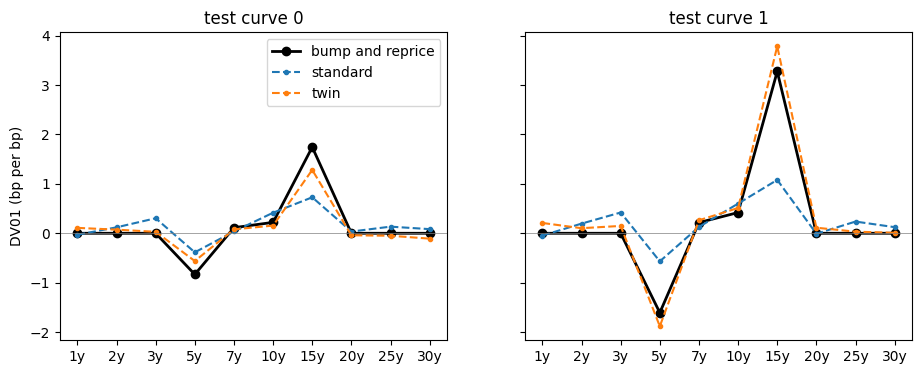

In [12]:
x, y, dydx = simulate_hw_swaption(4000, np.random.default_rng(7), this_swaption, hw)
standard = train(x, y, dydx, lambda_=0.0, seed=7)
twin = train(x, y, dydx, lambda_=1.0, seed=7)

x_test = sample_curves(100, np.random.default_rng(8), scale=0.8)
true_dv01 = np.array([bumped_dv01(c, this_swaption, hw) for c in x_test])
predicted = {name: m.predict(x_test)[1] for name, m in [("standard", standard), ("twin", twin)]}

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
pos = np.arange(len(PILLAR_NAMES))
for ax, k in zip(axes, [0, 1]):
    ax.plot(pos, true_dv01[k], "ko-", lw=2, label="bump and reprice")
    for name, dv01 in predicted.items():
        ax.plot(pos, dv01[k], "--", marker=".", label=name)
    ax.axhline(0, color="grey", lw=0.5)
    ax.set_xticks(pos)
    ax.set_xticklabels(PILLAR_NAMES)
    ax.set_title(f"test curve {k}")
axes[0].set_ylabel("DV01 (bp per bp)")
axes[0].legend()
plt.show()

Error per pillar vs error on the total (parallel) DV01:

In [13]:
print(f"correlation of the 5y and 15y pillars in the training curves: {np.corrcoef(x[:, 3], x[:, 6])[0, 1]:.2f}")
for name, dv01 in predicted.items():
    print(f"{name:9s} per-pillar DV01 RMSE {rmse(dv01, true_dv01):.3f}   parallel DV01 RMSE {rmse(dv01.sum(1), true_dv01.sum(1)):.3f}")
print(f"typical size of the parallel DV01: {np.abs(true_dv01.sum(1)).mean():.2f}")

correlation of the 5y and 15y pillars in the training curves: 0.95
standard  per-pillar DV01 RMSE 1.031   parallel DV01 RMSE 0.942
twin      per-pillar DV01 RMSE 0.103   parallel DV01 RMSE 0.282
typical size of the parallel DV01: 2.84


At 4k the standard net gets neither right. At 64k (below) its parallel error drops to 0.22 but per pillar stays at 1.32: it learns the total risk, not where it sits. Full results:

In [14]:
show_table("m4_rmse", ["n_train", "model", "price_rmse_bp", "dv01_rmse_bp", "parallel_dv01_rmse_bp"])
show_table("m4_timing")

n_train         model  price_rmse_bp  dv01_rmse_bp  parallel_dv01_rmse_bp
   1000      standard       110.3917        2.1325                 2.9252
   1000  differential        42.7107        0.2879                 1.0685
   4000      standard        59.3097        1.3952                 0.8687
   4000  differential        39.1383        0.1122                 0.5004
  16000      standard        21.7874        1.2225                 0.2511
  16000  differential        12.5575        0.0367                 0.1462
  64000      standard        19.8622        1.3156                 0.2205
  64000  differential         3.6084        0.0236                 0.0436
                                    method  microseconds_per_curve
bump and reprice (Jamshidian, 21 pricings)               2628.4316
network, batched forward and backward pass                  0.6633


The network is about 4,000x faster than bump and reprice, but Jamshidian is already cheap.

## 7. Early stopping

> **Paper, Section 2.1 (paraphrased).** The basket results use cross-validation and early stopping; the details are left to the authors' notebook.

4,000 steps on 1,000 samples overfits, so `train` holds out 20% and checks every 50 steps. Validation labels are noisy too, so I keep a later checkpoint unless it's worse by more than one standard error (my rule, not the paper's). Five seeds, 1,000 samples:

In [15]:
show_table("robustness_checks")

            problem         model          training  delta_rmse_mean  delta_rmse_min  delta_rmse_max
M2 basket, 7 assets      standard    early stopping           0.0878          0.0591          0.1214
M2 basket, 7 assets      standard  fixed 4000 steps           0.8365          0.6775          0.9603
M2 basket, 7 assets  differential    early stopping           0.0132          0.0068          0.0203
M2 basket, 7 assets  differential  fixed 4000 steps           0.0388          0.0279          0.0450
        M3 swaption      standard    early stopping           1.0970          0.7048          1.4413
        M3 swaption      standard  fixed 4000 steps           1.0336          0.6505          1.3012
        M3 swaption  differential    early stopping           0.2391          0.1694          0.3275
        M3 swaption  differential  fixed 4000 steps           0.2162          0.1609          0.3021


Fixes the basket, does nothing for the swaption.

## Summary

- Derivative labels give much better Greeks from the same data, more so with more inputs.
- On Hull-White it's the difference between getting the pillar DV01s and only the parallel risk.
- Prices are less reliable than Greeks, and noisy labels (vega) limit the gain.